# Comparison of the max points for different system 'losses'

In [1]:
#Imports
import qutip as qt
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#Initial/pi conditions:
param_steps = 30 #Steps for varried parameters
condition_steps = 50
theta_1 = np.pi
A_1 = np.pi
theta_2 = np.linspace(0,np.pi,condition_steps)
T0 = 0.01
delta0 = 0.01
sigma0 = 0.01

#Driven condition:
A_list = np.linspace(0,np.pi,condition_steps)
sig_list = np.linspace(0.001,2,param_steps)

#Time:
tlist = np.linspace(0, 10, 500)


#Hilbert space dimension:
N = 2


#Constants:
w = 1
w_k = 1 #Thermal bath frequency:
gamma = 1
t0 = 2


#Variables:
T_list = np.linspace(0.01,2,param_steps)
delta_list = np.linspace(0.01,2,param_steps) #Dephasing constant

#Creatrion/annihilation operator:
sigma = qt.destroy(N)
sigma_dag = sigma.dag()

In [3]:
#Define functions/hamiltonians:
def gaussian(t,args):
    
    a = args["a"]
    t0 = args["t0"]
    sig = args["sig"]

    return (a / (np.sqrt(2 * np.pi) * sig)*np.exp(-((t - t0)**2) / (2 * sig**2)))

def N_T(w_k, T):
    return  1 / (np.exp(w_k / T) - 1)#Assuming hbar, K_b = 1 


cops = [np.sqrt(gamma) * sigma]



cops_thermal0 = [(np.sqrt(gamma*(N_T(w_k, T0)+1))*sigma), 
                (np.sqrt(gamma*(N_T(w_k, T0)))*sigma.dag())]

cops_dephas0 = [np.sqrt(gamma) * sigma, 
               (np.sqrt(delta0)*(sigma_dag * sigma))] 



Ham = w*sigma_dag*sigma

H0 = w*sigma_dag*sigma
H1 = (sigma + sigma_dag)/2
#Nested list for QuTiP to interpret:
Ham_driven = [H0,[H1,gaussian]]

#Ground state:
ground = qt.basis(2,0) * qt.basis(2,0).dag() #Evolved state



def initial_state(theta):

    x = np.sin(theta)
    y = 0
    z = np.cos(theta)

    rho = 0.5 * (
        qt.qeye(2)
        + x * qt.sigmax()
        + y * qt.sigmay()
        + z * qt.sigmaz()
    )

    return rho


rho_1 = initial_state(theta_1)

rho_2 = []

for theta in theta_2:
    rho_2.append(initial_state(theta))

In [4]:
# Reference trajectories: fixed initial condition, all parameter values

Dist_drive0 = []
Dist_therm0 = []
Dist_dephas0 = []

#Here we are solving the Pi case of the gaussian over all parameters
#Then trace distance is computed and stored for later:
for sig in sig_list:
    args = {"a": np.pi, "t0": t0, "sig": sig}

    result = qt.mesolve(Ham_driven, ground, tlist, cops,
                        args=args, options={"max_step": sig / 10})
    
    Dist_drive0.append([qt.tracedist(rho, ground) for rho in result.states])

#Same is repeated here for Temp:
for temp in T_list:
    N_temp = N_T(w_k, temp)
    cops_thermal = [np.sqrt(gamma * (N_temp + 1)) * sigma,
                    np.sqrt(gamma * N_temp) * sigma.dag()]

    result = qt.mesolve(Ham, rho_1, tlist, cops_thermal)
    
    # Steady state for this temperature:
    rho_ss_thermal = qt.steadystate(Ham, cops_thermal)
    
    Dist_therm0.append([qt.tracedist(rho, rho_ss_thermal) for rho in result.states])

#Same for Dephasing:
for delta in delta_list:
    cops_dephas = [np.sqrt(gamma) * sigma,
                   np.sqrt(delta) * (sigma.dag() * sigma)]

    result = qt.mesolve(Ham, rho_1, tlist, cops_dephas)
    Dist_dephas0.append([qt.tracedist(rho, ground) for rho in result.states])

# Combine reference trajectories
Distances0 = np.array([
    Dist_drive0,
    Dist_therm0,
    Dist_dephas0
])

print(Distances0.shape)

(3, 30, 500)


In [5]:
#Gather data for three seperate sims:

results_driven = []
results_thermal = []
results_dephasing = []

for sig in sig_list:
    #Results list:
    sig_results = []
    
    for a in A_list:
        args = {"a": a, "t0": t0, "sig": sig} #Define here so one A value is passed through.
        result = qt.mesolve(Ham_driven,ground,tlist,cops, 
                            args=args, options={"max_step": sig / 10})#Make step small for small pulses.
        
        sig_results.append(result.states)
        
    results_driven.append(sig_results)

for temp in T_list:
    #Results list:
    temp_results = []
    
    #Construct collapse operators for each temp:
    cops_thermal = [(np.sqrt(gamma*(N_T(w_k, temp)+1))*sigma), 
                     (np.sqrt(gamma*(N_T(w_k, temp)))*sigma.dag())]
    
    # Steady state for this temperature:
    rho_ss_thermal = qt.steadystate(Ham, cops_thermal)
    
    for rh0 in rho_2:
        #Thermal:
        results = qt.mesolve(Ham,rh0,tlist,cops_thermal)
        
        #Calculate trace distance in the loop to make life easier:
        temp_results.append([
            qt.tracedist(state, rho_ss_thermal)
            for state in results.states
        ])
        
    results_thermal.append(temp_results)

        
for delta in delta_list:
    #Results list:
    dephas_results = []
    
    #Colapse operators:
    cops_dephas = [np.sqrt(gamma) * sigma, (np.sqrt(delta)*(sigma_dag * sigma))] 
    
    for rh0 in rho_2:
        #Dephasing:
        results = qt.mesolve(Ham,rh0,tlist,cops_dephas)
        
        dephas_results.append(results.states)
    results_dephasing.append(dephas_results)

In [6]:
#Calculate trace distances:
Dist_driven = np.array([[[qt.tracedist(rho, ground) for rho in trajectory]
        for trajectory in sig_results] for sig_results in results_driven])

Dist_thermal = results_thermal

Dist_dephasing = np.array([[[qt.tracedist(rho, ground) for rho in trajectory]
        for trajectory in dephas_results] for dephas_results in results_dephasing])

# Combine all three simulations
Distances = np.stack([
    Dist_driven,
    Dist_thermal,
    Dist_dephasing
])

In [7]:
Driven = Distances[0]

shifted_Dist = []
peak_idx = np.zeros((len(sig_list), len(A_list)), dtype=int)


for i in range(len(sig_list)):

    for j in range(len(A_list)):

        # Select one trajectory
        trajectory = Driven[i, j, :]

        # Index of maximum point
        max_index = np.argmax(trajectory)
        
        #Record the peak point:
        peak_idx[i, j] = max_index 
        
        # Ignore all values before the peak
        shifted_curve = trajectory[max_index:]
        
        #Add extra zeros to preserve shape
        shifted_curve = np.pad(
            shifted_curve,
            (0, len(tlist) - len(shifted_curve)),
            mode="constant"
        )
        
        
        shifted_Dist.append(shifted_curve)
        
Distances[0] = np.array(shifted_Dist).reshape(len(sig_list), 
                                              len(A_list), 
                                              len(tlist)) #Preserves shape!


#Shift the delta pulse case: 
shifted_ref = []
ref_peak = np.zeros(len(sig_list), dtype=int)

for z in range(len(sig_list)):
    trajectory = Distances0[0, z] #Driven reference for this sigma

    max_index = np.argmax(trajectory) #Index of the peak
    ref_peak[z] = max_index
    
    shifted_curve = trajectory[max_index:] #Ignore pre peak

    shifted_curve = np.pad(shifted_curve,
                           (0, len(tlist) - len(shifted_curve)),
                           mode="constant")   #Fill list with zeros

    shifted_ref.append(shifted_curve)

Distances0[0] = np.array(shifted_ref)

In [8]:
# Store maximum strength for each simulation and parameter
max_strength = np.zeros((len(Distances), Distances.shape[1]))
max_theta = np.zeros((len(Distances), Distances.shape[1]))

#Number of theta
n_a = Distances.shape[2] 

#Loop over each simulation type and parameters:
for k in range(len(Distances)): #Sweeps over simulations 
    
    for z in range(Distances.shape[1]): #Sweeps over parameters (ie. Temp)
        
        current_Dist = Distances[k, z] #Individual set of trajectories for each initial condition
        
        # theta=pi trajectory for this simulation
        pi_trajectory = Distances0[k, z]

        #To store once calculated: 
        strengths = []
        theta_values = []
        indices = []
        
        for i in range(n_a): #Sweeps over initial conditions
            
            #Curve used:
            curve_i = current_Dist[i, :] #Keeps all time point

            # driven: curves were shifted and padded
            if k == 0:   
                n = len(tlist) - max(peak_idx[z, i], ref_peak[z])
                
            # thermal/dephasing: not shifted  
            else:       
                n = len(tlist)
                
            # Difference between the two trajectories
            diff = curve_i[:n] - pi_trajectory[:n]

            diff_0 = diff[0]

            # Find crossing points
            crossing_points = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0]

            if len(crossing_points) > 0:

                first_cross = crossing_points[0]

                # Crossing time relative to t = 0
                crossing_time = tlist[first_cross] - tlist[0]

                if crossing_time > 0:
                    strength = abs(diff_0 / crossing_time)
                    strengths.append(strength)
                    
                    if k == 0:  # Driven
                        theta_values.append(A_list[i])
                    else:       # Thermal and dephasing
                        theta_values.append(theta_2[i])
                    
        # Save only the maximum strength and angle for this parameter:
        
        max_strength[k, z] = max(strengths, default=0)

        if strengths: #Checks if strengths has any values
            max_theta[k, z] = theta_values[strengths.index(max(strengths))]

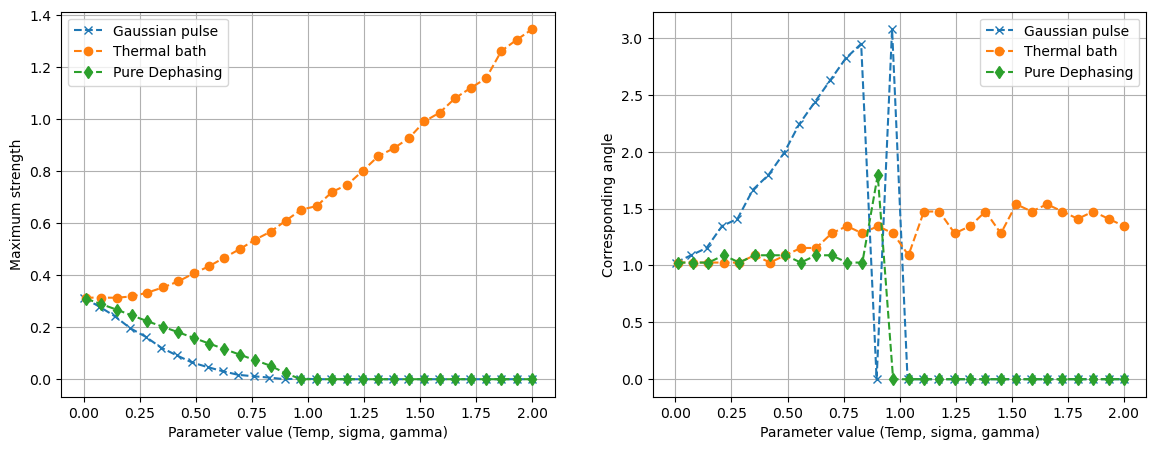

In [9]:
#Plot:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(sig_list, max_strength[0, :], marker = 'x', 
        linestyle = '--', label="Gaussian pulse")


ax1.plot(T_list, max_strength[1, :], marker = 'o', 
        linestyle = '--', label="Thermal bath")

ax1.plot(delta_list, max_strength[2, :], marker = 'd', 
        linestyle = '--', label="Pure Dephasing")

ax1.set_xlabel("Parameter value (Temp, sigma, gamma)")
ax1.set_ylabel("Maximum strength")
ax1.legend()
ax1.grid()

#Plot 2:

ax2.plot(sig_list, max_theta[0, :], marker = 'x', 
        linestyle = '--', label="Gaussian pulse")

ax2.plot(T_list, max_theta[1, :], marker = 'o', 
        linestyle = '--', label="Thermal bath")

ax2.plot(delta_list, max_theta[2, :], marker = 'd', 
        linestyle = '--', label="Pure Dephasing")

ax2.set_xlabel("Parameter value (Temp, sigma, gamma)")
ax2.set_ylabel("Corresponding angle")
ax2.legend()
ax2.grid()